In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

base_dir = Path(
    "/fast/AG_Metzger/philipp/python_files/gene_signature/"
    "mutual_information_approach/November_25_ReDo/"
    "preprocessing/pkl_files_filtered"
)


# ============================================================
# DATASETS
# ============================================================

file_dict = {
    "treutlein": base_dir / "treutlein_all_genes.pkl",
    "weinreb": base_dir / "weinreb_all_genes.pkl",
    "junker": base_dir / "junker_z5_all_genes.pkl",

    "you1": base_dir / "you_stage1_barcode_all_genes.pkl",
    "you2": base_dir / "you_stage2_barcode_all_genes.pkl",
    "you3": base_dir / "you_stage3_barcode_all_genes.pkl",
    "you4": base_dir / "you_stage4_barcode_all_genes.pkl",

    "knoblich_day16_1": base_dir / "knoblich_day16_1.pkl",
    "knoblich_day16_2": base_dir / "knoblich_day16_2.pkl",
    "knoblich_day42_1": base_dir / "knoblich_day42_1.pkl",
    "knoblich_day42_2": base_dir / "knoblich_day42_2.pkl",
}



MATCH_OUT_DIR = Path(
    "/fast/AG_Metzger/philipp/python_files/gene_signature/"
    "mutual_information_approach/November_25_ReDo/analysis/"
    "MT_set_level_matching"
)

MATCH_OUT_DIR.mkdir(parents=True, exist_ok=True)


name_map = {
    "treutlein": "HBO1",
    "weinreb": "MHSPC",
    "junker": "ZFL",

    "knoblich_day16_1": "HBO2_16_1",
    "knoblich_day16_2": "HBO2_16_2",
    "knoblich_day42_1": "HBO2_42_1",
    "knoblich_day42_2": "HBO2_42_2",

    "you1": "HBO3_1",
    "you2": "HBO3_2",
    "you3": "HBO3_3",
    "you4": "HBO3_4",
}

dataset_order = [
    "HBO1",
    "MHSPC",
    "ZFL",
    "HBO2_16_1",
    "HBO2_16_2",
    "HBO2_42_1",
    "HBO2_42_2",
    "HBO3_1",
    "HBO3_2",
    "HBO3_3",
    "HBO3_4",
]


N_MATCHED_SETS = 1000
RANDOM_SEED = 42

# Aim for <= 5% difference from MT set on EACH variable.
MATCH_TOLERANCE = 0.05

# Search settings
MAX_ATTEMPTS = 5000
N_OPTIMIZATION_STEPS = 5000

# Candidate genes closest to the MT-set covariate target
# are used for initialization/proposals.
SEARCH_POOL_SIZE = 5000

In [2]:
def calculate_gene_covariates(full_df):
    """
    Last dataframe column = lineage barcode.

    Returns one row per unique gene with:
        mean expression
        detection frequency
        expression variance
    """

    gene_data = full_df.iloc[:, :-1]

    rows = []

    for j, gene in enumerate(gene_data.columns):

        x = gene_data.iloc[:, j].to_numpy()

        rows.append({
            "gene": str(gene),
            "mean_expression": np.mean(x),
            "detection_frequency": np.mean(x > 0),
            "expression_variance": np.var(x),
        })

    gene_stats = pd.DataFrame(rows)

    # Collapse duplicate gene names
    gene_stats = (
        gene_stats
        .groupby("gene", as_index=False)
        .agg({
            "mean_expression": "mean",
            "detection_frequency": "mean",
            "expression_variance": "mean",
        })
    )

    gene_stats["is_MT"] = (
        gene_stats["gene"]
        .str.lower()
        .str.startswith("mt-")
    )

    return gene_stats

In [5]:
# ============================================================
# RECOVER A GOOD SEED SET FROM THE PREVIOUS SAVED MATCHING RUN
# ============================================================

best_match_genes = {}


for dataset in file_dict.keys():

    # These are the files produced by the previous
    # set-level matching run
    qc_path = (
        MATCH_OUT_DIR /
        f"{dataset}_matched_set_QC.csv"
    )

    genes_path = (
        MATCH_OUT_DIR /
        f"{dataset}_matched_gene_sets.csv"
    )


    qc = pd.read_csv(qc_path)
    genes = pd.read_csv(genes_path)


    if len(qc) == 0:
        raise ValueError(
            f"{dataset}: no previously matched sets available."
        )


    # --------------------------------------------------------
    # Find the previously generated set with the smallest
    # maximum mismatch across the 3 matching variables
    # --------------------------------------------------------

    best_row = (
        qc
        .sort_values("max_rel_error")
        .iloc[0]
    )

    best_set_id = int(
        best_row["set_id"]
    )


    seed_genes = (
        genes.loc[
            genes["set_id"] == best_set_id,
            "gene"
        ]
        .astype(str)
        .tolist()
    )


    best_match_genes[
        dataset
    ] = seed_genes


    print(
        dataset,
        "| seed set:",
        best_set_id,
        "| genes:",
        len(seed_genes),
        "| max error:",
        f"{100 * best_row['max_rel_error']:.3f}%"
    )

treutlein | seed set: 357 | genes: 13 | max error: 1.373%
weinreb | seed set: 1 | genes: 13 | max error: 4.894%
junker | seed set: 615 | genes: 13 | max error: 0.556%
you1 | seed set: 329 | genes: 13 | max error: 1.606%
you2 | seed set: 328 | genes: 13 | max error: 1.403%
you3 | seed set: 451 | genes: 13 | max error: 0.808%
you4 | seed set: 187 | genes: 13 | max error: 0.699%
knoblich_day16_1 | seed set: 297 | genes: 13 | max error: 1.659%
knoblich_day16_2 | seed set: 636 | genes: 13 | max error: 0.966%
knoblich_day42_1 | seed set: 334 | genes: 13 | max error: 0.907%
knoblich_day42_2 | seed set: 799 | genes: 13 | max error: 1.342%


In [12]:
# ============================================================
# RECOVER A GOOD SEED SET FROM THE PREVIOUS SAVED MATCHING RUN
# ============================================================

best_match_genes = {}


for dataset in file_dict.keys():

    # These are the files produced by the previous
    # set-level matching run
    qc_path = (
        MATCH_OUT_DIR /
        f"{dataset}_matched_set_QC.csv"
    )

    genes_path = (
        MATCH_OUT_DIR /
        f"{dataset}_matched_gene_sets.csv"
    )


    qc = pd.read_csv(qc_path)
    genes = pd.read_csv(genes_path)


    if len(qc) == 0:
        raise ValueError(
            f"{dataset}: no previously matched sets available."
        )


    # --------------------------------------------------------
    # Find the previously generated set with the smallest
    # maximum mismatch across the 3 matching variables
    # --------------------------------------------------------

    best_row = (
        qc
        .sort_values("max_rel_error")
        .iloc[0]
    )

    best_set_id = int(
        best_row["set_id"]
    )


    seed_genes = (
        genes.loc[
            genes["set_id"] == best_set_id,
            "gene"
        ]
        .astype(str)
        .tolist()
    )


    best_match_genes[
        dataset
    ] = seed_genes


    print(
        dataset,
        "| seed set:",
        best_set_id,
        "| genes:",
        len(seed_genes),
        "| max error:",
        f"{100 * best_row['max_rel_error']:.3f}%"
    )

treutlein | seed set: 357 | genes: 13 | max error: 1.373%
weinreb | seed set: 1 | genes: 13 | max error: 4.894%
junker | seed set: 615 | genes: 13 | max error: 0.556%
you1 | seed set: 329 | genes: 13 | max error: 1.606%
you2 | seed set: 328 | genes: 13 | max error: 1.403%
you3 | seed set: 451 | genes: 13 | max error: 0.808%
you4 | seed set: 187 | genes: 13 | max error: 0.699%
knoblich_day16_1 | seed set: 297 | genes: 13 | max error: 1.659%
knoblich_day16_2 | seed set: 636 | genes: 13 | max error: 0.966%
knoblich_day42_1 | seed set: 334 | genes: 13 | max error: 0.907%
knoblich_day42_2 | seed set: 799 | genes: 13 | max error: 1.342%


In [14]:
def generate_matched_sets_from_seed(
    gene_stats,
    seed_genes,
    n_sets=100,
    tolerance=0.05,
    target_error=0.01,
    n_optimization_steps=5000,
    n_perturb=2,
    random_seed=42
):
    """
    Generate diverse non-MT control sets starting from a good seed set.

    Matching uses ONLY:
        - mean expression
        - detection frequency
        - expression variance

    tolerance:
        Maximum allowed relative mismatch for an accepted set.

    target_error:
        Optimizer aims for this tighter mismatch before stopping.
    """

    rng = np.random.default_rng(random_seed)

    metrics = [
        "mean_expression",
        "detection_frequency",
        "expression_variance"
    ]

    # --------------------------------------------------------
    # MT and non-MT genes
    # --------------------------------------------------------

    mt_df = (
        gene_stats[gene_stats["is_MT"]]
        .copy()
        .reset_index(drop=True)
    )

    ctrl_df = (
        gene_stats[~gene_stats["is_MT"]]
        .copy()
        .reset_index(drop=True)
    )

    n_mt = len(mt_df)

    # --------------------------------------------------------
    # MT target values
    # --------------------------------------------------------

    target = (
        mt_df[metrics]
        .mean()
        .to_numpy(dtype=float)
    )

    scale = np.maximum(
        np.abs(target),
        1e-12
    )

    print("MT genes:", n_mt)
    print("Target set means:")
    print("  Expression:", target[0])
    print("  Detection: ", target[1])
    print("  Variance:  ", target[2])

    # --------------------------------------------------------
    # Control arrays
    # --------------------------------------------------------

    ctrl_values = (
        ctrl_df[metrics]
        .to_numpy(dtype=float)
    )

    ctrl_genes = (
        ctrl_df["gene"]
        .astype(str)
        .to_numpy()
    )

    gene_to_idx = {
        gene: i
        for i, gene in enumerate(ctrl_genes)
    }

    # --------------------------------------------------------
    # Seed genes -> indices
    # --------------------------------------------------------

    missing = [
        g for g in seed_genes
        if g not in gene_to_idx
    ]

    if missing:
        raise ValueError(
            f"Seed genes missing from controls: {missing}"
        )

    seed_idx = np.array(
        [gene_to_idx[g] for g in seed_genes],
        dtype=int
    )

    if len(seed_idx) != n_mt:
        raise ValueError(
            f"Seed has {len(seed_idx)} genes, "
            f"but MT set has {n_mt} genes."
        )

    # --------------------------------------------------------
    # Evaluate a set from its summed covariates
    # --------------------------------------------------------

    def evaluate_sum(current_sum):

        means = current_sum / n_mt

        signed_errors = (
            means - target
        ) / scale

        abs_errors = np.abs(
            signed_errors
        )

        score = abs_errors.max()

        return score, means, signed_errors

    # --------------------------------------------------------
    # Generate matched sets
    # --------------------------------------------------------

    accepted = []
    seen = set()

    attempts = 0
    max_attempts = n_sets * 100

    while (
        len(accepted) < n_sets
        and attempts < max_attempts
    ):

        attempts += 1

        # Start from good seed
        selected = seed_idx.copy()
        selected_set = set(selected.tolist())

        # ----------------------------------------------------
        # Perturb a few genes to create a new solution
        # ----------------------------------------------------

        positions = rng.choice(
            n_mt,
            size=min(n_perturb, n_mt),
            replace=False
        )

        for pos in positions:

            old_idx = selected[pos]

            while True:

                new_idx = rng.integers(
                    0,
                    len(ctrl_df)
                )

                if new_idx not in selected_set:
                    break

            selected_set.remove(old_idx)
            selected_set.add(new_idx)

            selected[pos] = new_idx

        current_sum = (
            ctrl_values[selected]
            .sum(axis=0)
        )

        current_score, _, _ = evaluate_sum(
            current_sum
        )

        # ----------------------------------------------------
        # Local swap optimization
        # ----------------------------------------------------

        for step in range(n_optimization_steps):

            # Stop only when we are VERY close,
            # not merely within the 5% acceptance threshold
            if current_score <= target_error:
                break

            out_pos = rng.integers(
                0,
                n_mt
            )

            old_idx = selected[out_pos]

            while True:

                new_idx = rng.integers(
                    0,
                    len(ctrl_df)
                )

                if new_idx not in selected_set:
                    break

            proposed_sum = (
                current_sum
                - ctrl_values[old_idx]
                + ctrl_values[new_idx]
            )

            proposed_score, _, _ = evaluate_sum(
                proposed_sum
            )

            if proposed_score < current_score:

                selected_set.remove(old_idx)
                selected_set.add(new_idx)

                selected[out_pos] = new_idx

                current_sum = proposed_sum
                current_score = proposed_score

        # ----------------------------------------------------
        # Final set
        # ----------------------------------------------------

        score, means, signed_errors = evaluate_sum(
            current_sum
        )

        if score <= tolerance:

            gene_tuple = tuple(
                sorted(ctrl_genes[selected])
            )

            if gene_tuple in seen:
                continue

            seen.add(gene_tuple)

            accepted.append({
                "set_id": len(accepted) + 1,

                "genes":
                    list(ctrl_genes[selected]),

                "mean_expression":
                    means[0],

                "detection_frequency":
                    means[1],

                "expression_variance":
                    means[2],

                "rel_error_expression":
                    signed_errors[0],

                "rel_error_detection":
                    signed_errors[1],

                "rel_error_variance":
                    signed_errors[2],

                "max_rel_error":
                    score
            })

        if attempts % 50 == 0:

            print(
                f"Attempts: {attempts} | "
                f"accepted: {len(accepted)}/{n_sets}",
                end="\r"
            )

    print()

    print(
        f"Found {len(accepted)} unique matched sets "
        f"after {attempts} attempts."
    )

    # --------------------------------------------------------
    # Convert results to dataframes
    # --------------------------------------------------------

    set_rows = []
    gene_rows = []

    for result in accepted:

        set_rows.append({
            key: value
            for key, value in result.items()
            if key != "genes"
        })

        for gene in result["genes"]:

            gene_rows.append({
                "set_id": result["set_id"],
                "gene": gene
            })

    set_summary = pd.DataFrame(set_rows)
    gene_selections = pd.DataFrame(gene_rows)

    return set_summary, gene_selections

In [17]:
# ============================================================
# PILOT: 100 SEEDED MATCHED SETS
# ============================================================


all_matched_qc = []
all_mt_qc = []

N_MATCHED_SETS = 100

tolerance = 0.03
target_error = 0.01
n_optimization_steps = 10000
n_perturb = 1

for dataset, pkl_path in file_dict.items():

    print("\n")
    print("=" * 75)
    print(dataset)
    print("=" * 75)

    # ========================================================
    # LOAD DATA
    # ========================================================

    full_df = pd.read_pickle(
        pkl_path
    )

    print(
        "Shape:",
        full_df.shape
    )

    # ========================================================
    # CALCULATE REVIEWER COVARIATES
    # ========================================================

    gene_stats = calculate_gene_covariates(
        full_df
    )

    del full_df

    print(
        "Genes:",
        len(gene_stats)
    )

    print(
        "MT genes:",
        gene_stats["is_MT"].sum()
    )

    # ========================================================
    # NEW SEEDED MATCHING
    #
    # best_match_genes comes from the MILP optimization
    # you already ran.
    # ========================================================

    set_summary, gene_selections = (
    generate_matched_sets_from_seed(

        gene_stats=gene_stats,

        seed_genes=best_match_genes[dataset],

        n_sets=N_MATCHED_SETS,

        tolerance=tolerance,

        target_error=target_error,

        n_optimization_steps=n_optimization_steps,

        n_perturb=n_perturb,

        random_seed=42
    )
    )

    # ========================================================
    # SAVE PILOT SETS
    # ========================================================

    gene_selections.to_csv(
        MATCH_OUT_DIR /
        f"{dataset}_matched_gene_sets_PILOT.csv",
        index=False
    )

    set_summary.to_csv(
        MATCH_OUT_DIR /
        f"{dataset}_matched_set_QC_PILOT.csv",
        index=False
    )

    # ========================================================
    # ADD DATASET INFO FOR QC PLOTS
    # ========================================================

    set_summary["dataset"] = dataset

    set_summary["dataset_label"] = (
        name_map[dataset]
    )

    all_matched_qc.append(
        set_summary
    )

    # ========================================================
    # OBSERVED MT SET
    # ========================================================

    mt_df = gene_stats[
        gene_stats["is_MT"]
    ]

    mt_qc = pd.DataFrame({

        "dataset":
            [dataset],

        "dataset_label":
            [name_map[dataset]],

        "mean_expression":
            [mt_df["mean_expression"].mean()],

        "detection_frequency":
            [mt_df["detection_frequency"].mean()],

        "expression_variance":
            [mt_df["expression_variance"].mean()]
    })

    all_mt_qc.append(
        mt_qc
    )

    # ========================================================
    # PRINT MATCH QUALITY
    # ========================================================

    print("\nMean matching errors:")

    print(
        "Expression:",
        100 * set_summary[
            "rel_error_expression"
        ].mean(),
        "%"
    )

    print(
        "Detection:",
        100 * set_summary[
            "rel_error_detection"
        ].mean(),
        "%"
    )

    print(
        "Variance:",
        100 * set_summary[
            "rel_error_variance"
        ].mean(),
        "%"
    )

    print(
        "Median maximum error:",
        100 * set_summary[
            "max_rel_error"
        ].median(),
        "%"
    )


# ============================================================
# COMBINE FOR YOUR EXISTING QC PLOTS
# ============================================================

matched_set_qc = pd.concat(
    all_matched_qc,
    ignore_index=True
)

mt_observed_qc = pd.concat(
    all_mt_qc,
    ignore_index=True
)



treutlein
Shape: (16506, 20857)
Genes: 20856
MT genes: 13
MT genes: 13
Target set means:
  Expression: 2.810386896133423
  Detection:  0.8498960750869148
  Variance:   0.6281047463417053
Attempts: 100 | accepted: 85/100
Found 100 unique matched sets after 115 attempts.

Mean matching errors:
Expression: -1.2350338320406746 %
Detection: 0.8036727733331885 %
Variance: 0.725075924147203 %
Median maximum error: 1.1782297708120886 %


weinreb
Shape: (49302, 22637)
Genes: 22636
MT genes: 13
MT genes: 13
Target set means:
  Expression: 2.9463553428649902
  Detection:  0.760721206504339
  Variance:   0.48698535561561584
Attempts: 10000 | accepted: 28/100
Found 28 unique matched sets after 10000 attempts.

Mean matching errors:
Expression: -2.8488293698594584 %
Detection: 2.8291847374802352 %
Variance: 0.026878089615233348 %
Median maximum error: 2.8858920262640204 %


junker
Shape: (6191, 21063)
Genes: 21062
MT genes: 13
MT genes: 13
Target set means:
  Expression: 1.6521949768066406
  Detec

In [18]:
def expand_feasible_matched_sets(
    gene_stats,
    seed_genes,
    n_sets=1000,
    tolerance=0.03,
    random_seed=42,
    max_steps=200000
):
    """
    Generate diverse matched control sets by random walking
    through the feasible set space.

    Every retained set:
        - has exactly the same number of genes as the MT set
        - contains only non-MT genes
        - differs by <= tolerance from the MT set for:
            * mean expression
            * detection frequency
            * expression variance

    MI is never used.
    """

    rng = np.random.default_rng(random_seed)

    metrics = [
        "mean_expression",
        "detection_frequency",
        "expression_variance"
    ]

    # ========================================================
    # MT / controls
    # ========================================================

    mt_df = (
        gene_stats[gene_stats["is_MT"]]
        .copy()
        .reset_index(drop=True)
    )

    ctrl_df = (
        gene_stats[~gene_stats["is_MT"]]
        .copy()
        .reset_index(drop=True)
    )

    n_mt = len(mt_df)

    target = (
        mt_df[metrics]
        .mean()
        .to_numpy(dtype=float)
    )

    scale = np.maximum(
        np.abs(target),
        1e-12
    )

    ctrl_values = (
        ctrl_df[metrics]
        .to_numpy(dtype=float)
    )

    ctrl_genes = (
        ctrl_df["gene"]
        .astype(str)
        .to_numpy()
    )

    gene_to_idx = {
        gene: i
        for i, gene in enumerate(ctrl_genes)
    }

    # ========================================================
    # Seed
    # ========================================================

    missing = [
        g for g in seed_genes
        if g not in gene_to_idx
    ]

    if missing:
        raise ValueError(
            f"Seed genes missing: {missing}"
        )

    selected = np.array(
        [gene_to_idx[g] for g in seed_genes],
        dtype=int
    )

    if len(selected) != n_mt:
        raise ValueError(
            f"Seed contains {len(selected)} genes; "
            f"expected {n_mt}."
        )

    current_sum = (
        ctrl_values[selected]
        .sum(axis=0)
    )

    # ========================================================
    # Evaluation
    # ========================================================

    def evaluate_sum(xsum):

        means = xsum / n_mt

        signed_error = (
            means - target
        ) / scale

        max_error = (
            np.abs(signed_error)
            .max()
        )

        return (
            max_error,
            means,
            signed_error
        )

    score, means, signed_error = evaluate_sum(
        current_sum
    )

    if score > tolerance:

        raise ValueError(
            f"Starting seed is not feasible: "
            f"{100 * score:.3f}% maximum mismatch."
        )

    # ========================================================
    # Save helper
    # ========================================================

    seen = set()

    set_rows = []
    gene_rows = []

    def save_current_set():

        key = tuple(
            sorted(
                ctrl_genes[selected]
            )
        )

        if key in seen:
            return False

        score, means, errors = evaluate_sum(
            current_sum
        )

        if score > tolerance:
            return False

        seen.add(key)

        set_id = len(seen)

        set_rows.append({
            "set_id": set_id,

            "mean_expression":
                means[0],

            "detection_frequency":
                means[1],

            "expression_variance":
                means[2],

            "rel_error_expression":
                errors[0],

            "rel_error_detection":
                errors[1],

            "rel_error_variance":
                errors[2],

            "max_rel_error":
                score
        })

        for gene in ctrl_genes[selected]:

            gene_rows.append({
                "set_id": set_id,
                "gene": gene
            })

        return True

    # save initial seed
    save_current_set()

    # ========================================================
    # FEASIBLE RANDOM WALK
    # ========================================================

    steps = 0

    while (
        len(seen) < n_sets
        and steps < max_steps
    ):

        steps += 1

        # -----------------------------------------------
        # Pick one gene to remove
        # -----------------------------------------------

        out_pos = rng.integers(
            0,
            n_mt
        )

        old_idx = selected[out_pos]

        sum_without = (
            current_sum
            - ctrl_values[old_idx]
        )

        # -----------------------------------------------
        # Evaluate every possible replacement simultaneously
        # -----------------------------------------------

        proposed_means = (
            sum_without[None, :]
            + ctrl_values
        ) / n_mt

        relative_errors = (
            proposed_means
            - target[None, :]
        ) / scale[None, :]

        max_errors = np.max(
            np.abs(relative_errors),
            axis=1
        )

        # candidate must satisfy the 3% constraint
        valid = (
            max_errors <= tolerance
        )

        # cannot add a gene already present
        valid[selected] = False

        candidate_idx = np.flatnonzero(
            valid
        )

        if len(candidate_idx) == 0:
            continue

        # -----------------------------------------------
        # Randomly choose among feasible replacements
        #
        # Slight preference for better matching while
        # retaining diversity.
        # -----------------------------------------------

        candidate_scores = (
            max_errors[candidate_idx]
        )

        weights = (
            tolerance
            - candidate_scores
            + 1e-6
        )

        weights = (
            weights /
            weights.sum()
        )

        new_idx = rng.choice(
            candidate_idx,
            p=weights
        )

        # -----------------------------------------------
        # Move to new feasible set
        # -----------------------------------------------

        selected[out_pos] = new_idx

        current_sum = (
            sum_without
            + ctrl_values[new_idx]
        )

        save_current_set()

        if steps % 1000 == 0:

            print(
                f"Steps: {steps} | "
                f"unique sets: {len(seen)}/{n_sets}",
                end="\r"
            )

    print()

    print(
        f"Finished with {len(seen)} unique sets "
        f"after {steps} feasible-swap steps."
    )

    return (
        pd.DataFrame(set_rows),
        pd.DataFrame(gene_rows)
    )

In [19]:
FINAL_MATCH_DIR = (
    MATCH_OUT_DIR
)


all_final_qc = []
all_final_mt = []


for dataset, pkl_path in file_dict.items():

    print("\n")
    print("=" * 75)
    print(dataset)
    print("=" * 75)

    # ========================================================
    # Gene covariates
    # ========================================================

    full_df = pd.read_pickle(
        pkl_path
    )

    gene_stats = calculate_gene_covariates(
        full_df
    )

    del full_df

    # ========================================================
    # Read the 3% pilot sets you just generated
    # ========================================================

    pilot_qc = pd.read_csv(
        MATCH_OUT_DIR /
        f"{dataset}_matched_set_QC_PILOT.csv"
    )

    pilot_genes = pd.read_csv(
        MATCH_OUT_DIR /
        f"{dataset}_matched_gene_sets_PILOT.csv"
    )

    # choose best pilot set as seed
    best_set_id = int(
        pilot_qc
        .sort_values("max_rel_error")
        .iloc[0]["set_id"]
    )

    seed_genes = (
        pilot_genes.loc[
            pilot_genes["set_id"] == best_set_id,
            "gene"
        ]
        .astype(str)
        .tolist()
    )

    print(
        "Starting seed max error:",
        100 * pilot_qc.loc[
            pilot_qc["set_id"] == best_set_id,
            "max_rel_error"
        ].iloc[0],
        "%"
    )

    # ========================================================
    # Generate final 1000 sets
    # ========================================================

    final_qc, final_genes = (
        expand_feasible_matched_sets(
            gene_stats=gene_stats,
            seed_genes=seed_genes,

            n_sets=1000,

            tolerance=0.03,

            random_seed=42,

            max_steps=200000
        )
    )

    # ========================================================
    # SAVE
    # ========================================================

    final_qc.to_csv(
        FINAL_MATCH_DIR /
        f"{dataset}_matched_set_QC_FINAL.csv",
        index=False
    )

    final_genes.to_csv(
        FINAL_MATCH_DIR /
        f"{dataset}_matched_gene_sets_FINAL.csv",
        index=False
    )

    # ========================================================
    # QC plotting objects
    # ========================================================

    final_qc["dataset"] = dataset
    final_qc["dataset_label"] = name_map[dataset]

    all_final_qc.append(
        final_qc
    )

    mt_df = gene_stats[
        gene_stats["is_MT"]
    ]

    all_final_mt.append(
        pd.DataFrame({
            "dataset": [dataset],
            "dataset_label": [name_map[dataset]],

            "mean_expression":
                [mt_df["mean_expression"].mean()],

            "detection_frequency":
                [mt_df["detection_frequency"].mean()],

            "expression_variance":
                [mt_df["expression_variance"].mean()]
        })
    )


matched_set_qc_final = pd.concat(
    all_final_qc,
    ignore_index=True
)

mt_observed_qc_final = pd.concat(
    all_final_mt,
    ignore_index=True
)



treutlein
Starting seed max error: 0.42765331292477 %

Finished with 1000 unique sets after 1278 feasible-swap steps.


weinreb
Starting seed max error: 2.3229062475899 %

Finished with 1000 unique sets after 2782 feasible-swap steps.


junker
Starting seed max error: 0.27347653843312 %
Steps: 1000 | unique sets: 984/1000
Finished with 1000 unique sets after 1016 feasible-swap steps.


you1
Starting seed max error: 0.28946245337987 %
Steps: 1000 | unique sets: 954/1000
Finished with 1000 unique sets after 1049 feasible-swap steps.


you2
Starting seed max error: 0.36382918792051 %
Steps: 1000 | unique sets: 928/1000
Finished with 1000 unique sets after 1078 feasible-swap steps.


you3
Starting seed max error: 0.23780463797786 %

Finished with 1000 unique sets after 1094 feasible-swap steps.


you4
Starting seed max error: 0.13591890026838 %
Steps: 1000 | unique sets: 892/1000
Finished with 1000 unique sets after 1118 feasible-swap steps.


knoblich_day16_1
Starting seed max error: 0.

In [20]:
# ============================================================
# FINAL MATCHING QC SUMMARY
# ============================================================

qc_summary = (
    matched_set_qc_final
    .groupby("dataset_label")
    .agg(
        n_sets=("set_id", "nunique"),

        mean_expr_error=("rel_error_expression", "mean"),
        max_expr_error=("rel_error_expression",
                        lambda x: np.abs(x).max()),

        mean_detection_error=("rel_error_detection", "mean"),
        max_detection_error=("rel_error_detection",
                             lambda x: np.abs(x).max()),

        mean_variance_error=("rel_error_variance", "mean"),
        max_variance_error=("rel_error_variance",
                            lambda x: np.abs(x).max()),

        max_overall_error=("max_rel_error", "max")
    )
    .reset_index()
)

# convert errors to %
error_cols = [
    c for c in qc_summary.columns
    if "error" in c
]

qc_summary[error_cols] *= 100

display(qc_summary)

,dataset_label,n_sets,mean_expr_error,max_expr_error,mean_detection_error,max_detection_error,mean_variance_error,max_variance_error,max_overall_error
0,HBO1,1000,-1.263511,2.996294,0.330790,2.954998,-0.492858,2.983858,2.996294
1,HBO2_16_1,1000,-0.623405,2.999873,-1.015254,2.991288,-1.643449,2.999430,2.999873
2,HBO2_16_2,1000,-0.954867,2.967018,0.256004,2.875943,-1.529517,2.986633,2.986633
3,HBO2_42_1,1000,-0.700815,2.949761,-0.400315,2.908177,-0.533931,2.913355,2.949761
4,HBO2_42_2,1000,-0.530812,2.959542,-0.873125,2.962028,-0.396409,2.927311,2.962028
5,HBO3_1,1000,-0.561614,2.974511,-1.048184,2.994823,-0.043549,2.945473,2.994823
6,HBO3_2,1000,-0.470839,2.919743,-0.372509,2.984355,-0.451869,2.986287,2.986287
7,HBO3_3,1000,-0.354020,2.960025,-0.777018,2.929643,-0.392121,2.987201,2.987201
8,HBO3_4,1000,-0.851093,2.986200,-0.473738,2.901290,-0.340087,2.990307,2.990307
9,MHSPC,1000,-2.647120,2.999367,2.125982,2.971290,0.527799,2.983044,2.999367


In [21]:
assert (qc_summary["n_sets"] == 1000).all()

assert (
    qc_summary["max_overall_error"] <= 3.000001
).all()

print("All datasets have 1000 sets and all sets satisfy the 3% criterion.")

All datasets have 1000 sets and all sets satisfy the 3% criterion.


In [22]:
def plot_matching_qc(
    metric,
    ylabel,
    log_scale=False
):

    fig, ax = plt.subplots(
        figsize=(12, 5)
    )

    sns.violinplot(
        data=matched_set_qc_final,
        x="dataset_label",
        y=metric,
        order=dataset_order,
        inner=None,
        cut=0,
        color="lightgray",
        ax=ax
    )

    for i, dataset in enumerate(dataset_order):

        value = mt_observed_qc_final.loc[
            mt_observed_qc_final["dataset_label"] == dataset,
            metric
        ].iloc[0]

        ax.scatter(
            i,
            value,
            color="black",
            s=55,
            zorder=5,
            label="MT genes" if i == 0 else None
        )

    ax.set_xlabel("")
    ax.set_ylabel(ylabel)

    if log_scale:
        ax.set_yscale("log")

    plt.xticks(
        rotation=45,
        ha="right"
    )

    ax.grid(False)
    sns.despine(ax=ax)

    ax.legend(
        frameon=False
    )

    plt.tight_layout()
    plt.show()

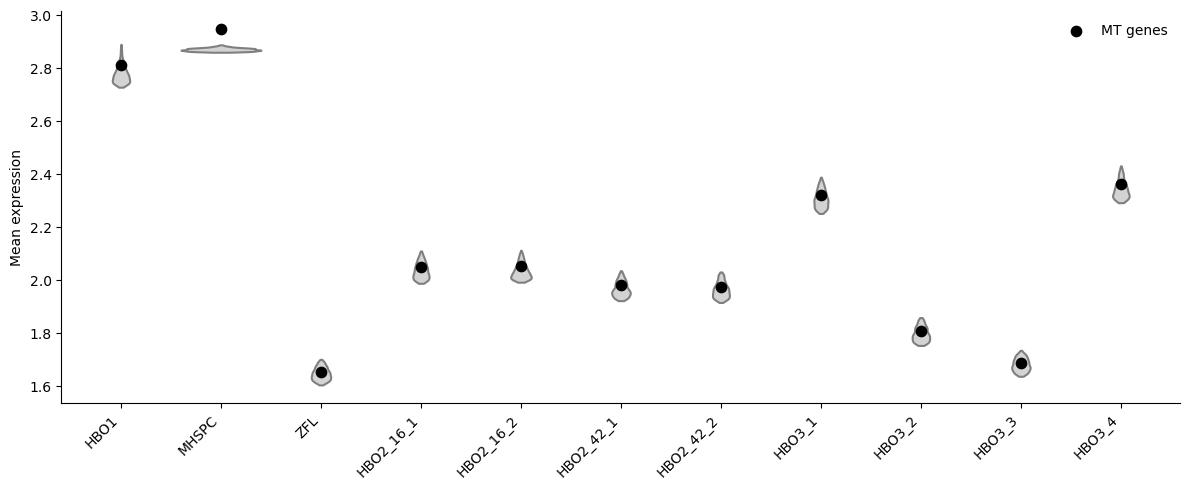

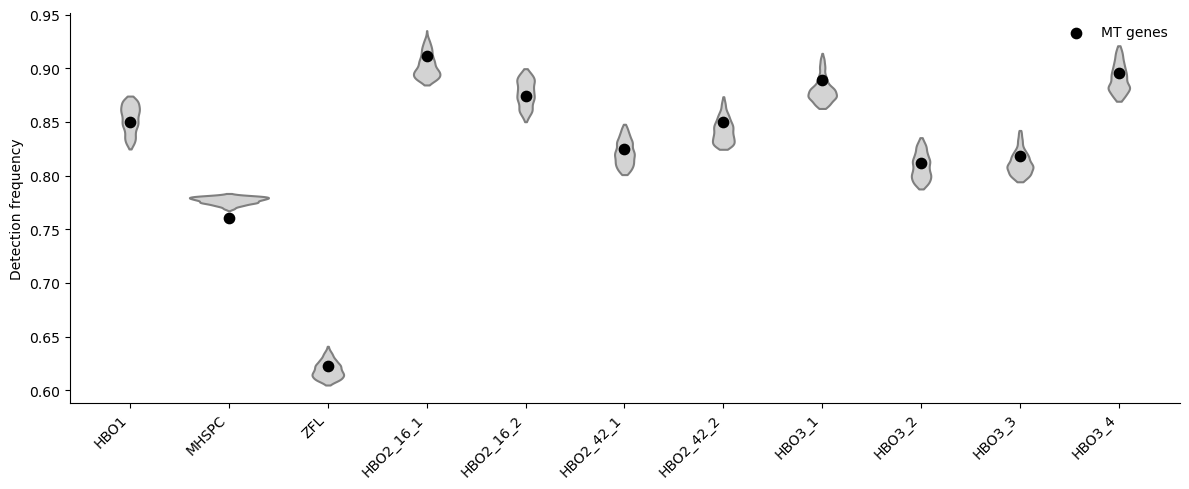

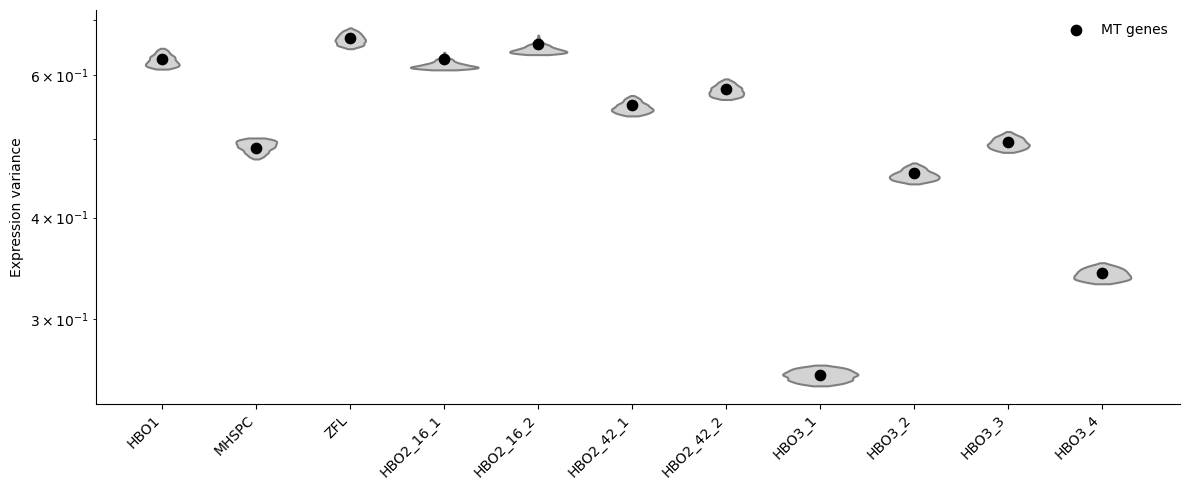

In [23]:
plot_matching_qc(
    "mean_expression",
    "Mean expression"
)

plot_matching_qc(
    "detection_frequency",
    "Detection frequency"
)

plot_matching_qc(
    "expression_variance",
    "Expression variance",
    log_scale=True
)

In [24]:
from pathlib import Path
import numpy as np
import pandas as pd

from statsmodels.stats.multitest import multipletests


# ============================================================
# SETTINGS
# ============================================================

MI_COL = "true_mi"

MI_DIR = Path(
    "/fast/AG_Metzger/philipp/python_files/gene_signature/"
    "mutual_information_approach/November_25_ReDo/calc_files/MI/"
    "mi_analysis_results_MI_label_entropy_all_genes_parallel"
)

MI_MATCH_OUT_DIR = MATCH_OUT_DIR / "MI_results"

MI_MATCH_OUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


all_summaries = []


# ============================================================
# LOOP OVER DATASETS
# ============================================================

for dataset in file_dict.keys():

    print("\n")
    print("=" * 75)
    print(dataset)
    print("=" * 75)


    # ========================================================
    # LOAD MI VALUES
    # ========================================================

    mi_path = (
        MI_DIR /
        f"MI_label_entropy_{dataset}_50_permutations.csv"
    )

    mi_df = pd.read_csv(
        mi_path
    )

    if "gene" not in mi_df.columns:
        raise ValueError(
            f"{dataset}: no 'gene' column in MI file."
        )

    if MI_COL not in mi_df.columns:
        raise ValueError(
            f"{dataset}: no '{MI_COL}' column in MI file.\n"
            f"Columns: {list(mi_df.columns)}"
        )


    mi_lookup = (
        mi_df[
            [
                "gene",
                MI_COL
            ]
        ]
        .copy()
    )

    mi_lookup["gene"] = (
        mi_lookup["gene"]
        .astype(str)
    )

    # safety against duplicate genes
    mi_lookup = (
        mi_lookup
        .groupby(
            "gene",
            as_index=False
        )[MI_COL]
        .max()
        .set_index("gene")[MI_COL]
    )


    # ========================================================
    # GET MT GENES
    # ========================================================

    full_df = pd.read_pickle(
        file_dict[dataset]
    )

    gene_names = (
        full_df.columns[:-1]
        .astype(str)
    )

    del full_df


    mt_genes = [
        g
        for g in pd.unique(gene_names)
        if g.lower().startswith("mt-")
    ]


    # Keep only MT genes present in the MI results
    mt_genes = [
        g
        for g in mt_genes
        if g in mi_lookup.index
    ]


    print(
        "MT genes with MI:",
        len(mt_genes)
    )

    print(
        mt_genes
    )


    if len(mt_genes) == 0:
        raise ValueError(
            f"{dataset}: no MT genes found in MI table."
        )


    # ========================================================
    # OBSERVED MT MEAN MI
    # ========================================================

    mt_mi_values = (
        mi_lookup.loc[
            mt_genes
        ]
        .to_numpy()
    )


    mt_mean_mi = (
        mt_mi_values.mean()
    )

    mt_median_mi = (
        np.median(
            mt_mi_values
        )
    )


    # ========================================================
    # LOAD FINAL MATCHED SETS
    # ========================================================

    matched_genes_path = (
        MATCH_OUT_DIR /
        f"{dataset}_matched_gene_sets_FINAL.csv"
    )

    matched_genes = pd.read_csv(
        matched_genes_path
    )

    matched_genes["gene"] = (
        matched_genes["gene"]
        .astype(str)
    )


    # ========================================================
    # ADD MI TO EACH MATCHED GENE
    # ========================================================

    matched_genes["mi"] = (
        matched_genes["gene"]
        .map(
            mi_lookup
        )
    )


    n_missing = (
        matched_genes["mi"]
        .isna()
        .sum()
    )


    print(
        "Matched gene rows missing MI:",
        n_missing
    )


    if n_missing > 0:

        missing_genes = (
            matched_genes.loc[
                matched_genes["mi"].isna(),
                "gene"
            ]
            .unique()
        )

        print(
            "Missing genes:",
            missing_genes
        )

        raise ValueError(
            f"{dataset}: some matched genes have no MI."
        )


    # ========================================================
    # MEAN MI FOR EACH OF THE 1000 MATCHED SETS
    # ========================================================

    matched_set_mi = (
        matched_genes
        .groupby(
            "set_id",
            as_index=False
        )
        .agg(
            mean_mi=("mi", "mean"),
            median_mi=("mi", "median"),
            n_genes=("gene", "nunique")
        )
    )


    print(
        "Matched sets:",
        len(matched_set_mi)
    )

    print(
        "Genes per set:",
        matched_set_mi["n_genes"].unique()
    )


    # ========================================================
    # EMPIRICAL ONE-SIDED P VALUE
    #
    # H1:
    # MT genes have higher mean MI than matched controls
    # ========================================================

    n_sets = len(
        matched_set_mi
    )


    empirical_p_mean = (
        1
        +
        np.sum(
            matched_set_mi["mean_mi"]
            >= mt_mean_mi
        )
    ) / (
        n_sets + 1
    )


    empirical_p_median = (
        1
        +
        np.sum(
            matched_set_mi["median_mi"]
            >= mt_median_mi
        )
    ) / (
        n_sets + 1
    )


    # ========================================================
    # EFFECT SIZE
    # ========================================================

    matched_mean_mi = (
        matched_set_mi[
            "mean_mi"
        ]
        .mean()
    )


    mi_ratio = (
        mt_mean_mi
        /
        matched_mean_mi
    )


    mi_difference = (
        mt_mean_mi
        -
        matched_mean_mi
    )


    # ========================================================
    # SAVE DISTRIBUTION
    # ========================================================

    matched_set_mi.to_csv(
        MI_MATCH_OUT_DIR /
        f"{dataset}_MT_expression_matched_MI_distribution.csv",
        index=False
    )


    # ========================================================
    # SUMMARY
    # ========================================================

    all_summaries.append({

        "dataset":
            dataset,

        "n_MT_genes":
            len(mt_genes),

        "n_matched_sets":
            n_sets,

        "MT_mean_MI":
            mt_mean_mi,

        "matched_mean_MI":
            matched_mean_mi,

        "MI_difference":
            mi_difference,

        "MI_ratio_MT_over_matched":
            mi_ratio,

        "empirical_p_mean":
            empirical_p_mean,

        "MT_median_MI":
            mt_median_mi,

        "matched_median_MI":
            matched_set_mi[
                "median_mi"
            ].mean(),

        "empirical_p_median":
            empirical_p_median
    })


    print(
        "\nMT mean MI:",
        mt_mean_mi
    )

    print(
        "Matched mean MI:",
        matched_mean_mi
    )

    print(
        "Ratio:",
        mi_ratio
    )

    print(
        "Empirical p:",
        empirical_p_mean
    )



treutlein
MT genes with MI: 13
['MT-ND1', 'MT-ND2', 'MT-CO1', 'MT-CO2', 'MT-ATP8', 'MT-ATP6', 'MT-CO3', 'MT-ND3', 'MT-ND4L', 'MT-ND4', 'MT-ND5', 'MT-ND6', 'MT-CYB']
Matched gene rows missing MI: 0
Matched sets: 1000
Genes per set: [13]

MT mean MI: 1.8623838933996724
Matched mean MI: 1.6842394847301572
Ratio: 1.1057714240074694
Empirical p: 0.000999000999000999


weinreb
MT genes with MI: 13
['mt-Atp6', 'mt-Atp8', 'mt-Co1', 'mt-Co2', 'mt-Co3', 'mt-Cytb', 'mt-Nd1', 'mt-Nd2', 'mt-Nd3', 'mt-Nd4', 'mt-Nd4l', 'mt-Nd5', 'mt-Nd6']
Matched gene rows missing MI: 0
Matched sets: 1000
Genes per set: [13]

MT mean MI: 1.20175267883406
Matched mean MI: 1.2840226155217096
Ratio: 0.9359279691080654
Empirical p: 1.0


junker
MT genes with MI: 13
['mt-nd1', 'mt-nd2', 'mt-co1', 'mt-co2', 'mt-atp8', 'mt-atp6', 'mt-co3', 'mt-nd3', 'mt-nd4l', 'mt-nd4', 'mt-nd5', 'mt-nd6', 'mt-cyb']
Matched gene rows missing MI: 0
Matched sets: 1000
Genes per set: [13]

MT mean MI: 0.4505400944252536
Matched mean MI: 0.42

In [25]:
mi_summary_df = pd.DataFrame(
    all_summaries
)


# ============================================================
# BH correction across 11 independent dataset-level tests
# ============================================================

mi_summary_df["p_BH"] = multipletests(
    mi_summary_df[
        "empirical_p_mean"
    ],
    method="fdr_bh"
)[1]


mi_summary_df["significant_BH"] = (
    mi_summary_df["p_BH"]
    < 0.05
)


# ============================================================
# Dataset labels
# ============================================================

mi_summary_df["dataset_label"] = (
    mi_summary_df["dataset"]
    .map(name_map)
)


# nice order
mi_summary_df["dataset_label"] = pd.Categorical(
    mi_summary_df["dataset_label"],
    categories=dataset_order,
    ordered=True
)

mi_summary_df = (
    mi_summary_df
    .sort_values("dataset_label")
    .reset_index(drop=True)
)


# ============================================================
# SAVE
# ============================================================

summary_path = (
    MI_MATCH_OUT_DIR /
    "MT_expression_detection_variance_matched_MI_summary.csv"
)

mi_summary_df.to_csv(
    summary_path,
    index=False
)


display(
    mi_summary_df
)

print(
    "\nSaved:",
    summary_path
)

,dataset,n_MT_genes,n_matched_sets,MT_mean_MI,matched_mean_MI,MI_difference,MI_ratio_MT_over_matched,empirical_p_mean,MT_median_MI,matched_median_MI,empirical_p_median,p_BH,significant_BH,dataset_label
0,treutlein,13,1000,1.862384,1.684239,0.178144,1.105771,0.000999,2.003176,1.778094,0.000999,0.003663,True,HBO1
1,weinreb,13,1000,1.201753,1.284023,-0.082270,0.935928,1.000000,1.435407,1.544962,1.000000,1.000000,False,MHSPC
2,junker,13,1000,0.450540,0.426118,0.024422,1.057313,0.035964,0.534058,0.481184,0.028971,0.079121,False,ZFL
3,knoblich_day16_1,13,1000,0.328699,0.327499,0.001200,1.003663,0.416583,0.350396,0.333538,0.001998,0.458242,False,HBO2_16_1
4,knoblich_day16_2,13,1000,0.257324,0.249714,0.007611,1.030478,0.082917,0.275815,0.252209,0.000999,0.130298,False,HBO2_16_2
5,knoblich_day42_1,13,1000,0.137553,0.135034,0.002519,1.018654,0.171828,0.139018,0.146597,0.966034,0.236264,False,HBO2_42_1
6,knoblich_day42_2,13,1000,0.234254,0.228128,0.006127,1.026856,0.081918,0.238033,0.235397,0.378621,0.130298,False,HBO2_42_2
7,you1,13,1000,3.809954,3.538523,0.271432,1.076708,0.000999,4.062013,3.631332,0.000999,0.003663,True,HBO3_1
8,you2,13,1000,3.561663,3.370154,0.191510,1.056825,0.026973,4.011997,3.472629,0.000999,0.074176,False,HBO3_2
9,you3,13,1000,3.302046,3.050917,0.251129,1.082313,0.000999,3.709125,3.192561,0.000999,0.003663,True,HBO3_3



Saved: /fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/analysis/MT_set_level_matching/MI_results/MT_expression_detection_variance_matched_MI_summary.csv


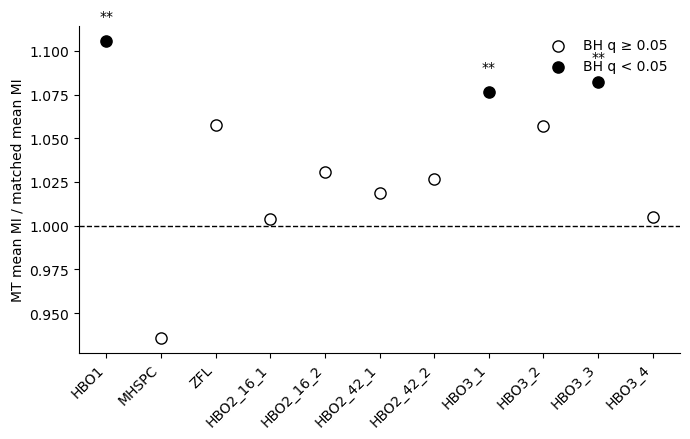

In [26]:
import matplotlib.pyplot as plt
import numpy as np


plot_df = (
    mi_summary_df
    .copy()
)


fig, ax = plt.subplots(
    figsize=(7, 4.5)
)


x = np.arange(
    len(plot_df)
)


# no enrichment
ax.axhline(
    1,
    linestyle="--",
    linewidth=1,
    color="black"
)


# non-significant
ns = (
    ~plot_df["significant_BH"]
)

ax.scatter(
    x[ns],
    plot_df.loc[
        ns,
        "MI_ratio_MT_over_matched"
    ],
    facecolors="white",
    edgecolors="black",
    s=65,
    zorder=3,
    label="BH q ≥ 0.05"
)


# significant
sig = (
    plot_df["significant_BH"]
)

ax.scatter(
    x[sig],
    plot_df.loc[
        sig,
        "MI_ratio_MT_over_matched"
    ],
    color="black",
    s=65,
    zorder=3,
    label="BH q < 0.05"
)


# ============================================================
# STARS
# ============================================================

for i, row in plot_df.iterrows():

    q = row["p_BH"]

    if q < 0.001:
        stars = "***"

    elif q < 0.01:
        stars = "**"

    elif q < 0.05:
        stars = "*"

    else:
        stars = ""


    if stars:

        ax.text(
            i,
            row[
                "MI_ratio_MT_over_matched"
            ] + 0.01,
            stars,
            ha="center",
            va="bottom"
        )


# ============================================================
# FORMAT
# ============================================================

ax.set_xticks(
    x
)

ax.set_xticklabels(
    plot_df[
        "dataset_label"
    ],
    rotation=45,
    ha="right"
)

ax.set_ylabel(
    "MT mean MI / matched mean MI"
)

ax.set_xlabel("")

ax.spines[
    "top"
].set_visible(False)

ax.spines[
    "right"
].set_visible(False)

ax.legend(
    frameon=False
)

plt.tight_layout()
plt.show()